# 02 - Preprocessing

Build the filtered Summer/Snow pair table, verify the shared RGB normalization, and precompute geographic hard negatives for training.

In [2]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tifffile

REPO_DIR = Path.cwd()
if not (REPO_DIR / "src").is_dir():
    REPO_DIR = REPO_DIR.parent
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

from src.preprocessing.data_cleaner import attach_splits, load_pairs
from src.preprocessing.hard_negative_mining import precompute_hard_negatives
from src.preprocessing.normalization import normalize_rgb
from src.preprocessing.schema import HardNegatives, Pairs

DATA_DIR = Path(os.environ.get("SEASONET_DIR", REPO_DIR / "data")).resolve()
ARTIFACTS_DIR = REPO_DIR / "artifacts"
ARTIFACTS_DIR.mkdir(exist_ok=True)

In [3]:
pairs = attach_splits(load_pairs(DATA_DIR), DATA_DIR)
train_pairs = pairs[pairs[Pairs.SPLIT] == "train"].reset_index(drop=True)

print(f"all pairs: {len(pairs):,}")
print(f"training pairs: {len(train_pairs):,}")
print(pairs[Pairs.SPLIT].value_counts())

all pairs: 80,897
training pairs: 56,672
split
train    56672
test     16121
val       8104
Name: count, dtype: int64


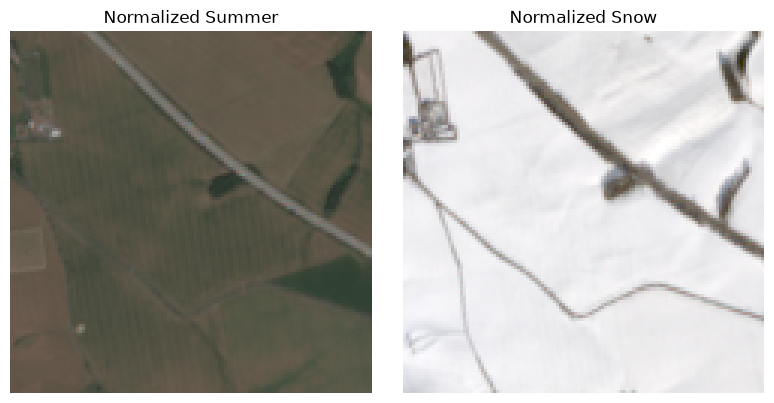

In [5]:
def load_rgb(rel_path):
    tile_dir = DATA_DIR / rel_path
    return tifffile.imread(next(tile_dir.glob("*_10m_RGB.tif")))

sample = train_pairs.sample(1, random_state=0).iloc[0]
summer_rgb = normalize_rgb(load_rgb(sample[Pairs.PATH_SUMMER]), gamma=True)
snow_rgb = normalize_rgb(load_rgb(sample[Pairs.PATH_SNOW]), gamma=True)

assert summer_rgb.dtype == np.float32
assert snow_rgb.dtype == np.float32
assert 0 <= summer_rgb.min() and summer_rgb.max() <= 1
assert 0 <= snow_rgb.min() and snow_rgb.max() <= 1

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(summer_rgb)
axes[0].set_title("Normalized Summer")
axes[1].imshow(snow_rgb)
axes[1].set_title("Normalized Snow")
for ax in axes:
    ax.axis("off")
plt.tight_layout()

In [5]:
K = 50
CANDIDATE_COUNT = 100
EXCLUSION_RADIUS_M = 2_000
OUTPUT_PATH = ARTIFACTS_DIR / f"hard_negatives_k{K}_exclusion_radius{EXCLUSION_RADIUS_M}m.parquet"

hard_negatives = precompute_hard_negatives(
    train_pairs,
    k=K,
    candidate_count=CANDIDATE_COUNT,
    exclusion_radius_m=EXCLUSION_RADIUS_M,
)
hard_negatives.to_parquet(OUTPUT_PATH, index=False)

per_anchor = hard_negatives.groupby(HardNegatives.ANCHOR_LOC_ID).size()
print(f"saved {len(hard_negatives):,} hard-negative relationships to {OUTPUT_PATH}")
print(f"Parquet size: {OUTPUT_PATH.stat().st_size / 1024 ** 2:.1f} MiB")
print(per_anchor.describe())

saved 2,833,600 hard-negative relationships to /Users/wynnson/Documents/dev/Season-Agnostic-Geolocation-Embeddings/artifacts/hard_negatives_k50_exclusion_radius2000m.parquet
Parquet size: 61.1 MiB
count    56672.0
mean        50.0
std          0.0
min         50.0
25%         50.0
50%         50.0
75%         50.0
max         50.0
dtype: float64
